# Regression finding the explaining factors for grounding and solving time

In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score

import matplotlib.pyplot as plt
import ast

results = pd.read_csv('main-results.csv')
results['clue_type_counts'] = results['clue_type_counts'].apply(ast.literal_eval)

In [2]:
#linear regression on the most important variables
#results = pd.DataFrame(results_choice)

dependent_variables = ['ground_time', 'solve_time']
independent_variables = ['grid_size', 'clue_count', 'grounded_at']
independent_variables_to_dummies = ['type', 'choice_type', 'constraint_type']

clue_generalization_dict = {
            'in_top_row': 'specific row/column',\
            'in_bottom_row': 'specific row/column',\
            'in_left_column': 'specific row/column',\
            'in_right_column': 'specific row/column',\
            'in_column': 'specific row/column',\
            'in_row': 'specific row/column',\

            'in_room_with_multiple_females': 'in room with multiple males/females',\
            'in_room_with_multiple_males': 'in room with multiple males/females',\

            'in_room_with_female': 'in room with male/female',\
            'in_room_with_male': 'in room with male/female',\

            'not_in_room_with_female': 'not in room with male/female',\
            'not_in_room_with_male': 'not in room with male/female',\

            'east_of': 'nesw of',\
            'west_of': 'nesw of',\
            'north_of': 'nesw of',\
            'south_of': 'nesw of',\

            'n_east_of': 'n nesw of',\
            'n_west_of': 'n nesw of',\
            'n_north_of': 'n nesw of',\
            'n_south_of': 'n nesw of',\

            'object_in_col': 'object in row/column',\
            'object_in_row': 'object in row/column',\

            'no_object_in_col': 'no object in row/column',\
            'no_object_in_row': 'no object in row/column'}

clue_counts_all = pd.json_normalize(results['clue_type_counts']).set_index(results.index)
sum_mapping = {}
for old_col, new_col in clue_generalization_dict.items():
    sum_mapping.setdefault(new_col, []).append(old_col)

for new_col, columns_to_combine in sum_mapping.items():
    valid_cols = [c for c in columns_to_combine if c in clue_counts_all.columns]
    if valid_cols:
        clue_counts_all[new_col] = clue_counts_all[valid_cols].sum(axis=1, min_count=1)

clue_counts_all = clue_counts_all.drop(columns=[key for key in clue_generalization_dict.keys()], errors='ignore')
clue_counts_all = clue_counts_all.fillna(0)

results_dummies = pd.get_dummies(results[independent_variables_to_dummies], drop_first=True, dtype=int)
results_indep = results[independent_variables].copy()

results_for_linreg = pd.concat([results_indep, results_dummies, clue_counts_all, results[dependent_variables]], axis=1)

In [3]:
results_for_linreg.columns

Index(['grid_size', 'clue_count', 'grounded_at', 'number_of_cells', 'type_M',
       'choice_type_Python', 'constraint_type_Aggregate constraints',
       'constraint_type_Python', 'next_to', 'in', 'not_in', 'only_one_on',
       'on', 'alone', 'in_corner', 'in_same_room', 'n_persons_on',
       'next_to_with_someone_else', 'no_empty_room', 'not_next_to',
       'someone_else_in_room_on', 'someone_else_in_room_next_to',
       'object_in_same_room', 'not_on', 'not_in_corner', 'not_in_same_room',
       'not_alone', 'specific row/column',
       'in room with multiple males/females', 'in room with male/female',
       'not in room with male/female', 'nesw of', 'n nesw of',
       'object in row/column', 'no object in row/column', 'ground_time',
       'solve_time'],
      dtype='str')



RESULTS FOR ground_time, normal ASP


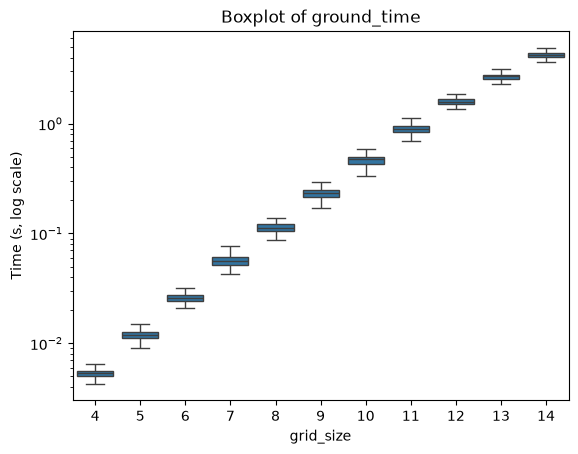

Root Mean Squared Error (RMSE): 0.17
R-squared: 0.99
                                Feature  Coefficient  Absolute_Impact
0                             grid_size     2.263362         2.263362
2                                    in    -0.078191         0.078191
1                               next_to    -0.052184         0.052184
20                  specific row/column    -0.030750         0.030750
5                                    on    -0.025805         0.025805
27              no object in row/column    -0.025377         0.025377
8                          in_same_room    -0.017843         0.017843
7                             in_corner    -0.014417         0.014417
4                           only_one_on     0.013033         0.013033
9                          n_persons_on     0.012163         0.012163
10            next_to_with_someone_else     0.008391         0.008391
18                     not_in_same_room     0.007183         0.007183
6                                 alo

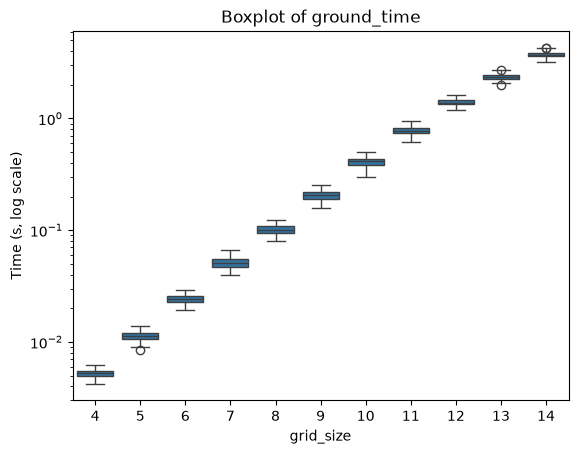

Root Mean Squared Error (RMSE): 0.15
R-squared: 0.99
                                Feature  Coefficient  Absolute_Impact
0                             grid_size     2.218940         2.218940
2                                    in    -0.069691         0.069691
1                               next_to    -0.050710         0.050710
20                  specific row/column    -0.028554         0.028554
5                                    on    -0.023145         0.023145
27              no object in row/column    -0.022768         0.022768
8                          in_same_room    -0.016863         0.016863
9                          n_persons_on     0.012158         0.012158
7                             in_corner    -0.010509         0.010509
4                           only_one_on     0.010363         0.010363
10            next_to_with_someone_else     0.008667         0.008667
17                        not_in_corner    -0.006487         0.006487
18                     not_in_same_ro

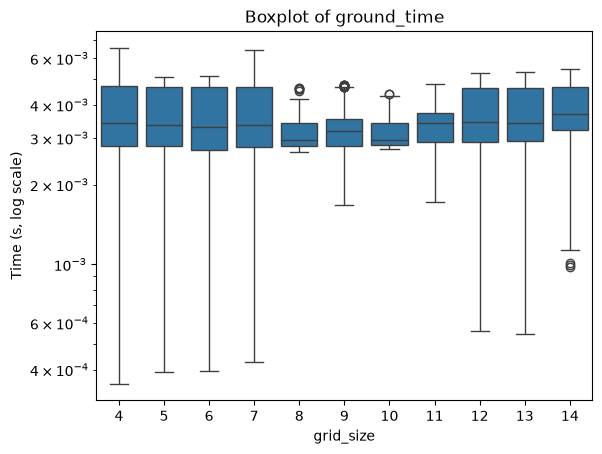

Root Mean Squared Error (RMSE): 0.56
R-squared: 0.04
                                Feature  Coefficient  Absolute_Impact
0                             grid_size     0.073254         0.073254
10            next_to_with_someone_else    -0.036345         0.036345
26                 object in row/column    -0.024592         0.024592
12                          not_next_to     0.020577         0.020577
14         someone_else_in_room_next_to     0.020545         0.020545
1                               next_to     0.019712         0.019712
19                            not_alone    -0.019432         0.019432
5                                    on    -0.019350         0.019350
3                                not_in    -0.016885         0.016885
22             in room with male/female    -0.016314         0.016314
25                            n nesw of    -0.015391         0.015391
2                                    in    -0.012922         0.012922
11                        no_empty_ro

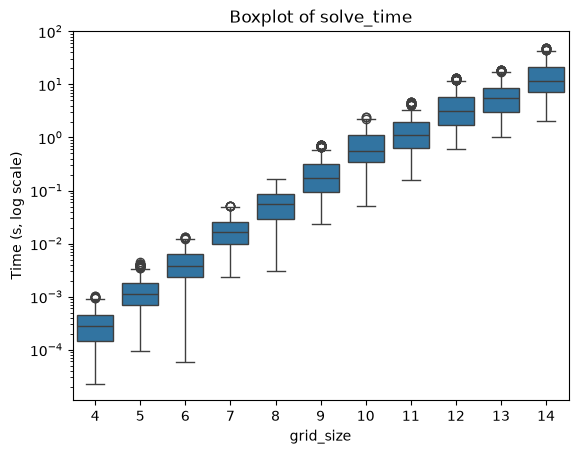

Root Mean Squared Error (RMSE): 0.82
R-squared: 0.95
                                Feature  Coefficient  Absolute_Impact
0                             grid_size     3.435716         3.435716
2                                    in    -0.190477         0.190477
25                            n nesw of     0.186503         0.186503
8                          in_same_room     0.129953         0.129953
5                                    on    -0.127753         0.127753
24                              nesw of     0.119764         0.119764
14         someone_else_in_room_next_to     0.111484         0.111484
1                               next_to    -0.108681         0.108681
19                            not_alone     0.101295         0.101295
20                  specific row/column    -0.096688         0.096688
22             in room with male/female     0.083854         0.083854
21  in room with multiple males/females     0.078619         0.078619
11                        no_empty_ro

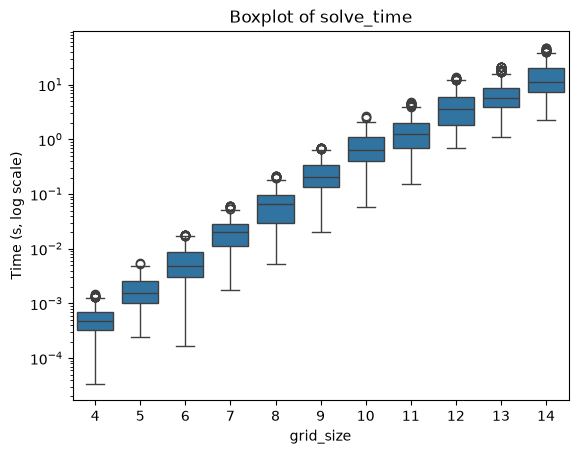

Root Mean Squared Error (RMSE): 0.69
R-squared: 0.96
                                Feature  Coefficient  Absolute_Impact
0                             grid_size     3.386685         3.386685
2                                    in    -0.198520         0.198520
1                               next_to    -0.136812         0.136812
20                  specific row/column    -0.127135         0.127135
24                              nesw of     0.122340         0.122340
25                            n nesw of     0.118248         0.118248
5                                    on    -0.112939         0.112939
8                          in_same_room     0.109350         0.109350
14         someone_else_in_room_next_to     0.092253         0.092253
10            next_to_with_someone_else     0.079188         0.079188
19                            not_alone     0.076733         0.076733
21  in room with multiple males/females     0.066892         0.066892
4                           only_one_

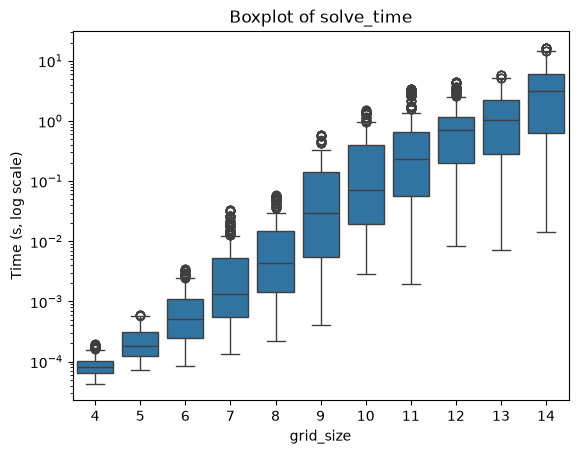

Root Mean Squared Error (RMSE): 1.14
R-squared: 0.90
                                Feature  Coefficient  Absolute_Impact
0                             grid_size     4.137066         4.137066
2                                    in    -0.659858         0.659858
1                               next_to    -0.591618         0.591618
5                                    on    -0.474218         0.474218
20                  specific row/column    -0.427090         0.427090
25                            n nesw of     0.274450         0.274450
9                          n_persons_on     0.260108         0.260108
8                          in_same_room     0.252948         0.252948
7                             in_corner    -0.170115         0.170115
14         someone_else_in_room_next_to     0.157913         0.157913
4                           only_one_on     0.157667         0.157667
10            next_to_with_someone_else     0.148694         0.148694
21  in room with multiple males/femal

In [7]:

#Actual regression

dep_value = 'solve_time'


def outlier_mask(x):
    Q1 = x.quantile(0.25)
    Q3 = x.quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    return (x >= lower) & (x <= upper)

for dep_value in ['ground_time', 'solve_time']:
    for method in ['normal ASP','agg ASP','Python']:

        if method == 'normal ASP':
            results_filter = (results_for_linreg['constraint_type_Python'] == 0) & (results_for_linreg['constraint_type_Aggregate constraints'] == 0) #& (results_for_linreg['grid_size'] == 10)
        elif method == 'agg ASP':
            results_filter = (results_for_linreg['constraint_type_Python'] == 0) & (results_for_linreg['constraint_type_Aggregate constraints'] == 1) #& (results_for_linreg['grid_size'] == 10)
        else:
            results_filter = (results_for_linreg['constraint_type_Python'] == 1) & (results_for_linreg['constraint_type_Aggregate constraints'] == 0) #& (results_for_linreg['grid_size'] == 10)

        results_for_linreg_subset = results_for_linreg[results_filter]

        print(f'\n\n================================================\nRESULTS FOR {dep_value}, {method}\n================================================')


        valid_rows_mask = results_for_linreg_subset.groupby('grid_size')[dep_value].transform(outlier_mask)
        results_for_linreg_subset = results_for_linreg_subset[valid_rows_mask].reset_index(drop=True)

        import seaborn as sns
        ax = sns.boxplot(y=dep_value, x='grid_size', data = results_for_linreg_subset)
        ax.set_yscale('log')
        ax.set_ylabel('Time (s, log scale)')
        plt.title(f'Boxplot of {dep_value}')
        plt.show()

        y = np.log(results_for_linreg_subset[dep_value])

        X = results_for_linreg_subset[['grid_size',
                'next_to', 'in', 'not_in', 'only_one_on',
                'on', 'alone', 'in_corner', 'in_same_room', 'n_persons_on',
                'next_to_with_someone_else', 'no_empty_room', 'not_next_to',
                'someone_else_in_room_on', 'someone_else_in_room_next_to',
                'object_in_same_room', 'not_on', 'not_in_corner', 'not_in_same_room',
                'not_alone', 'specific row/column',
                'in room with multiple males/females', 'in room with male/female',
                'not in room with male/female', 'nesw of', 'n nesw of',
                'object in row/column', 'no object in row/column']]



        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=0)
        scaler = StandardScaler()
        X_train_scaled = scaler.fit_transform(X_train)
        X_test_scaled = scaler.transform(X_test)

        model = LinearRegression()
        model.fit(X_train_scaled, y_train)

        predictions = model.predict(X_test_scaled)

        rmse = np.sqrt(mean_squared_error(y_test, predictions))
        r2 = r2_score(y_test, predictions)

        print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
        print(f"R-squared: {r2:.2f}")


        importance_df = pd.DataFrame({
            'Feature': X.columns,
            'Coefficient': model.coef_,
            'Absolute_Impact': np.abs(model.coef_)
        }).sort_values(by='Absolute_Impact', ascending=False)

        print(importance_df)


        from sklearn.inspection import permutation_importance

        baseline_mse = mean_squared_error(y_test, predictions)

        results = permutation_importance(
            model, X_test_scaled, y_test,
            n_repeats=30,                      # more repeats = more stable estimate
            random_state=42,
            scoring='neg_mean_squared_error'
        )

        perm_df = pd.DataFrame({
            'Feature': X.columns,
            'MSE_increase_mean': results.importances_mean,
            'MSE_increase_std': results.importances_std,
            'MSE_increase_pct': 100 * results.importances_mean / baseline_mse,
        }).sort_values(by='MSE_increase_mean', ascending=False)

        print(f"Baseline test MSE: {baseline_mse:.4f}")
        print(perm_df.to_string(index=False))